# 4. Clustering, and deciding whether to believe it

*Part of the [broadlisten](https://github.com/InteractionDataLab/broad-listening/tree/main/code)
stage-by-stage examples. Every number and figure below was produced by running
this notebook on the synthetic corpus in `broadlisten.sample`, which is
generated from templates and contains no participant data.*

Two methods with opposite failure modes are provided on purpose. **Ward** puts
every response in a theme, including responses that belong in none. **HDBSCAN**
leaves those unplaced, which is more honest and more awkward, because the
unplaced share then has to be reported next to every percentage.

Which to believe is decided by diagnostics, not by which produced the tidier
picture.

In [1]:
from sklearn.metrics import adjusted_rand_score
from broadlisten.sample import sample_corpus, sample_embeddings, THEMES

corpus = sample_corpus(seed=0)
vectors = sample_embeddings(corpus.planted_theme.tolist(), seed=0)
truth = corpus.planted_theme.astype("category").cat.codes.values
themed = corpus.planted_theme.notna().values
print(f"{len(corpus)} responses, {len(THEMES)} planted themes, "
      f"{int((~themed).sum())} blank or junk")

600 responses, 5 planted themes, 74 blank or junk


## Ward, and the one-standard-error rule

The plain argmax of the silhouette curve overfits: silhouette is noisy across
`k`. The one-standard-error rule takes the simplest `k` within one standard
error of the best, which is the smaller, more defensible answer.

In [2]:
from broadlisten.cluster import choose_k, ward_labels

selection = choose_k(vectors[themed], k_min=2, k_max=10, verbose=False)
print(f"one-standard-error rule chose k={selection['k']}")
print(f"the plain argmax would have said k={selection['best_k']}")

ward = ward_labels(vectors[themed], len(THEMES))
print(f"\nARI against the planted truth at the true k: "
      f"{adjusted_rand_score(truth[themed], ward):.3f}")

one-standard-error rule chose k=5
the plain argmax would have said k=5

ARI against the planted truth at the true k: 1.000


## HDBSCAN, and the responses it refuses to place

The unplaced share is not a failure. It is the responses that sit in no dense
region, usually because they raise several subjects at once, and dropping them
silently changes every denominator downstream.

In [3]:
from broadlisten.cluster import hdbscan_cluster, noise_summary

labels, info = hdbscan_cluster(vectors, min_cluster_size=15)
summary = noise_summary(labels)
print(f"{summary['n_clusters']} themes, {summary['n_noise']} unplaced "
      f"({summary['noise_share']:.1%})")
print(f"sizes: {summary['sizes']}")

  HDBSCAN mcs=15 method=eom: 5 clusters, 75 noise (12.5%), DBCV=0.0364
5 themes, 75 unplaced (12.5%)
sizes: {0: 114, 1: 93, 2: 112, 3: 121, 4: 85}


## Do the clusters survive resampling?

A cluster that dissolves when you remove a fifth of the data is a property of
this sample, not of the population.

In [4]:
from broadlisten.cluster import bootstrap_ari, cluster_jaccard, internal_scores

stability = bootstrap_ari(vectors, lambda A: hdbscan_cluster(A, min_cluster_size=15,
                                                             verbose=False)[0],
                          n_resamples=30, seed=42)
print(f"bootstrap ARI {stability['mean']:.3f} "
      f"[{stability['lo']:.3f}, {stability['hi']:.3f}]")

placed = labels != -1
print(f"internal scores: {internal_scores(vectors[placed], labels[placed])}")

bootstrap ARI 0.999 [0.995, 1.000]
internal scores: {'silhouette': 0.27029699087142944, 'calinski_harabasz': 111.96696444108129, 'davies_bouldin': 1.4476532762675254, 'n_clusters': 5, 'n_scored': 525}


In [5]:
per_cluster = cluster_jaccard(
    vectors, lambda A: hdbscan_cluster(A, min_cluster_size=15, verbose=False)[0],
    n_resamples=30, seed=42)
per_cluster

,cluster,size,jaccard_mean,jaccard_lo,jaccard_hi,n_resamples,stable
0,0,114,1.000000,1.000000,1.0,30,True
1,1,93,1.000000,1.000000,1.0,30,True
2,3,121,1.000000,1.000000,1.0,30,True
3,4,85,1.000000,1.000000,1.0,30,True
4,2,112,0.997662,0.987598,1.0,30,True


## The grade

Every theme carries a tier saying what it may be used for. **Claimable** survived
everything. **Descriptive** means mention it, do not test it. **Artifact** means
the label itself failed verification, and its label is never printed.

In [6]:
from IPython.display import Image

def png(fig, w=900, h=480):
    """Render a figure as a static PNG.

    GitHub's notebook viewer does not run Plotly, so an interactive figure is a
    blank cell to anyone reading this on the web. A PNG is visible to everyone.
    """
    return Image(fig.to_image(format="png", width=w, height=h, scale=2))

In [7]:
from broadlisten.evidence import build_evidence_table
from broadlisten.explore import category_bars

frame = corpus[placed].copy()
frame["cluster"] = labels[placed]
frame["clean"] = frame.text.astype(str)
frame["n_words"] = frame["clean"].str.split().str.len()

table = build_evidence_table(
    frame, level="sub", id_col="cluster",
    jaccard=dict(zip(per_cluster.cluster, per_cluster.jaccard_mean)))
print(table.tier.value_counts().to_string())
table[["id", "tier", "n_participants", "n_teams", "jaccard", "reason"]]

tier
DESCRIPTIVE    5


,id,tier,n_participants,n_teams,jaccard,reason
0,3,DESCRIPTIVE,49,15.0,1.000000,not verifiable: naming audit and label verific...
1,0,DESCRIPTIVE,47,13.0,1.000000,not verifiable: naming audit and label verific...
2,2,DESCRIPTIVE,46,13.0,0.997662,not verifiable: naming audit and label verific...
3,4,DESCRIPTIVE,41,12.0,1.000000,not verifiable: naming audit and label verific...
4,1,DESCRIPTIVE,37,12.0,1.000000,not verifiable: naming audit and label verific...


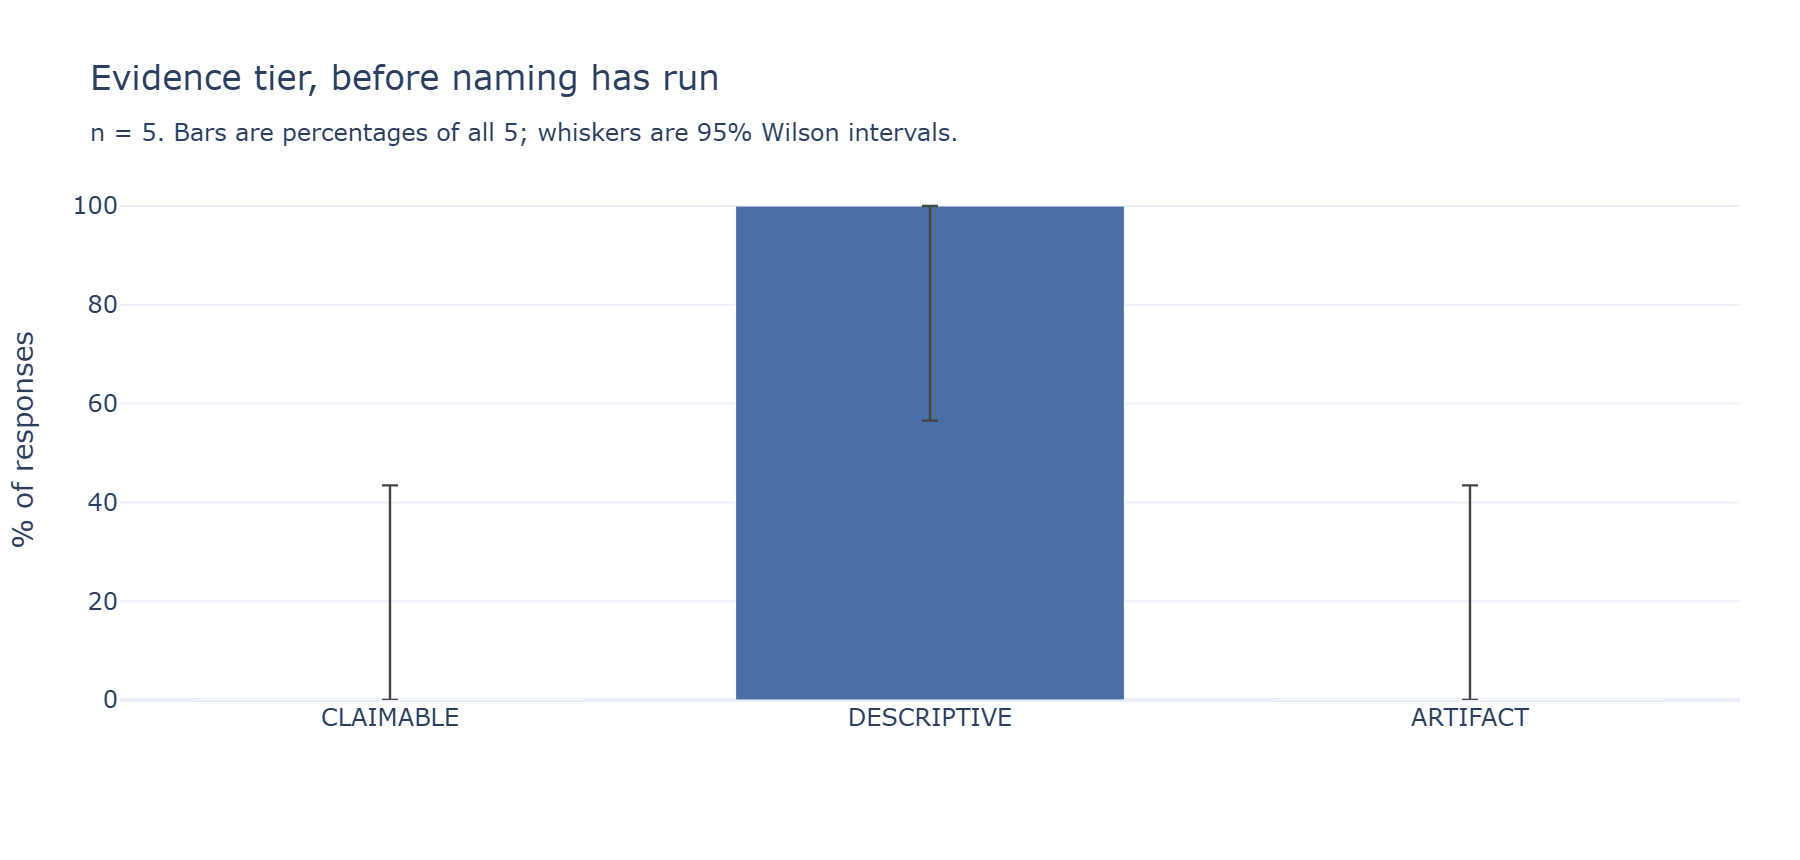

In [8]:
png(category_bars(table.tier.value_counts().to_dict(),
                  order=["CLAIMABLE", "DESCRIPTIVE", "ARTIFACT"],
                  title="Evidence tier, before naming has run"), h=430)

Nothing is Claimable yet, and that is correct: a theme cannot be
Claimable until a **name** has survived its checks, which is the next notebook.

**Next:** [5. Naming](05_name.ipynb).